In [8]:
import warnings
warnings.filterwarnings(action='ignore')

import seaborn as sns
import pandas as pd
import numpy as np

from scipy import stats
from statsmodels.formula.api import ols, glm
import statsmodels.api as sm
import matplotlib.pyplot as plt

In [3]:
penguins = sns.load_dataset('penguins')

## 종 구분 안하고 plot

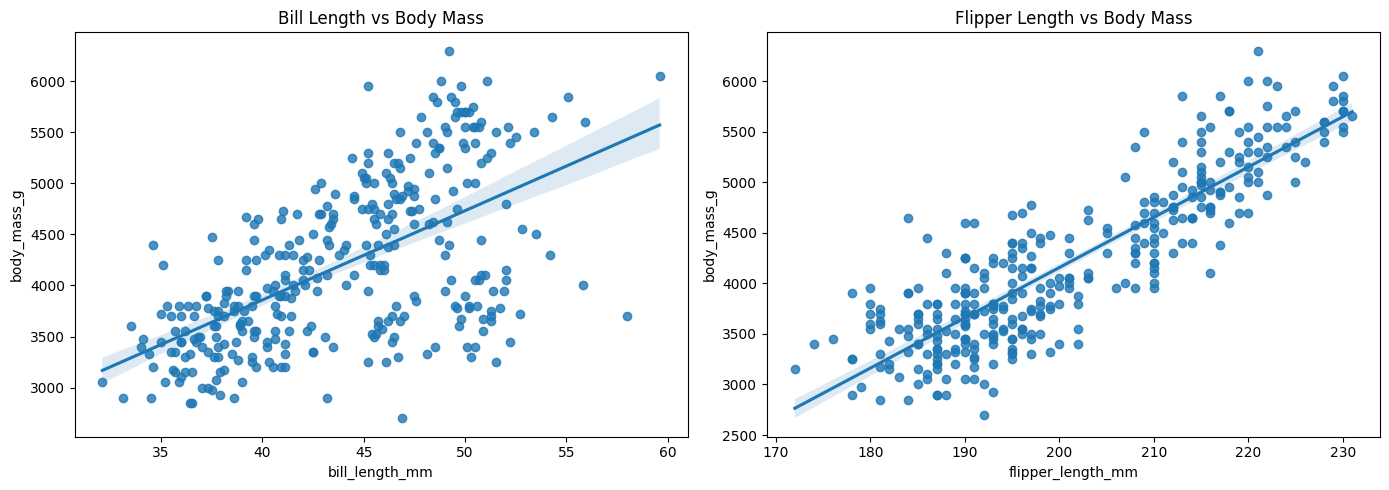

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# bill_length
sns.regplot(
    data=penguins,
    x='bill_length_mm',
    y='body_mass_g',
    ax=axes[0]
)

axes[0].set_title('Bill Length vs Body Mass')

# flipper_length
sns.regplot(
    data=penguins,
    x='flipper_length_mm',
    y='body_mass_g',
    ax=axes[1]
)

axes[1].set_title('Flipper Length vs Body Mass')

plt.tight_layout()
plt.show()

## 종별 plot

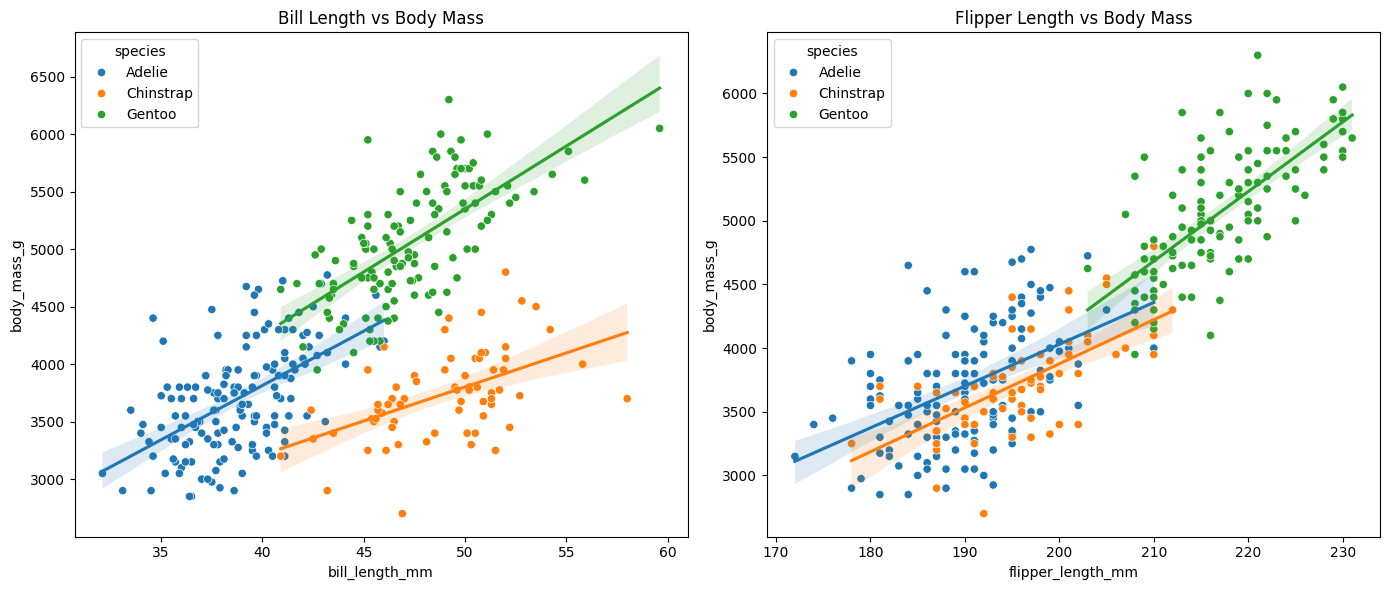

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6)
)

# bill_length
sns.scatterplot(
    data=penguins,
    x='bill_length_mm',
    y='body_mass_g',
    hue='species',
    ax=axes[0]
)

for sp in penguins['species'].dropna().unique():
    sns.regplot(
        data=penguins[penguins['species'] == sp],
        x='bill_length_mm',
        y='body_mass_g',
        scatter=False,
        ax=axes[0]
    )

axes[0].set_title('Bill Length vs Body Mass')

# flipper_length
sns.scatterplot(
    data=penguins,
    x='flipper_length_mm',
    y='body_mass_g',
    hue='species',
    ax=axes[1]
)

for sp in penguins['species'].dropna().unique():
    sns.regplot(
        data=penguins[penguins['species'] == sp],
        x='flipper_length_mm',
        y='body_mass_g',
        scatter=False,
        ax=axes[1]
    )

axes[1].set_title('Flipper Length vs Body Mass')

plt.tight_layout()
plt.show()


## 실습문제 plot

In [9]:
penguins['body_mass_kg'] = penguins['body_mass_g'] * 0.001

# ols

Rformula = 'body_mass_kg ~ bill_length_mm + flipper_length_mm + species'

regression_result = ols(Rformula, data = penguins).fit()

regression_result.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           body_mass_kg   R-squared:                       0.822
Model:                            OLS   Adj. R-squared:                  0.820
Method:                 Least Squares   F-statistic:                     389.7
Date:                Fri, 12 Jun 2026   Prob (F-statistic):          5.50e-125
Time:                        10:13:58   Log-Likelihood:                -113.92
No. Observations:                 342   AIC:                             237.8
Df Residuals:                     337   BIC:                             257.0
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               -3.9044      0.529     -7.377      0.000      -4.945      -2.863
species[T.Chinstrap]    -0.7486      0.082     -9.181      0.000      -0.909      -0.588
species[T.Gentoo]        0.0904      0.089      1.020      0.308      -0.084       0.265
bill_length_mm           0.0617      0.007      8.664      0.000       0.048       0.076
flipper_length_mm        0.0274      0.003      8.638      0.000       0.021       0.034
==============================================================================
Omnibus:                        4.644   Durbin-Watson:                   2.333
Prob(Omnibus):                  0.098   Jarque-Bera (JB):                4.553
Skew:                           0.282   Prob(JB):                        0.103
Kurtosis:                       3.021   Cond. No.                     5.99e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 5.99e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [10]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

penguins2 = penguins.dropna().copy()

species_list = penguins2['species'].unique()

# 공통 고정값
mean_bill = penguins2['bill_length_mm'].mean()
mean_flipper = penguins2['flipper_length_mm'].mean()

# x축 범위
bill_range = np.linspace(
    penguins2['bill_length_mm'].min(),
    penguins2['bill_length_mm'].max(),
    100
)

flipper_range = np.linspace(
    penguins2['flipper_length_mm'].min(),
    penguins2['flipper_length_mm'].max(),
    100
)

# 예측용 데이터프레임 만들기
pred_list = []

for sp in species_list:
    
    temp_bill = pd.DataFrame({
        'bill_length_mm': bill_range,
        'flipper_length_mm': mean_flipper,
        'species': sp,
        'feature': 'bill'
    })
    
    temp_flipper = pd.DataFrame({
        'bill_length_mm': mean_bill,
        'flipper_length_mm': flipper_range,
        'species': sp,
        'feature': 'flipper'
    })
    
    pred_list.append(temp_bill)
    pred_list.append(temp_flipper)

pred_df = pd.concat(pred_list, ignore_index=True)

pred_df['pred'] = regression_result.predict(pred_df)

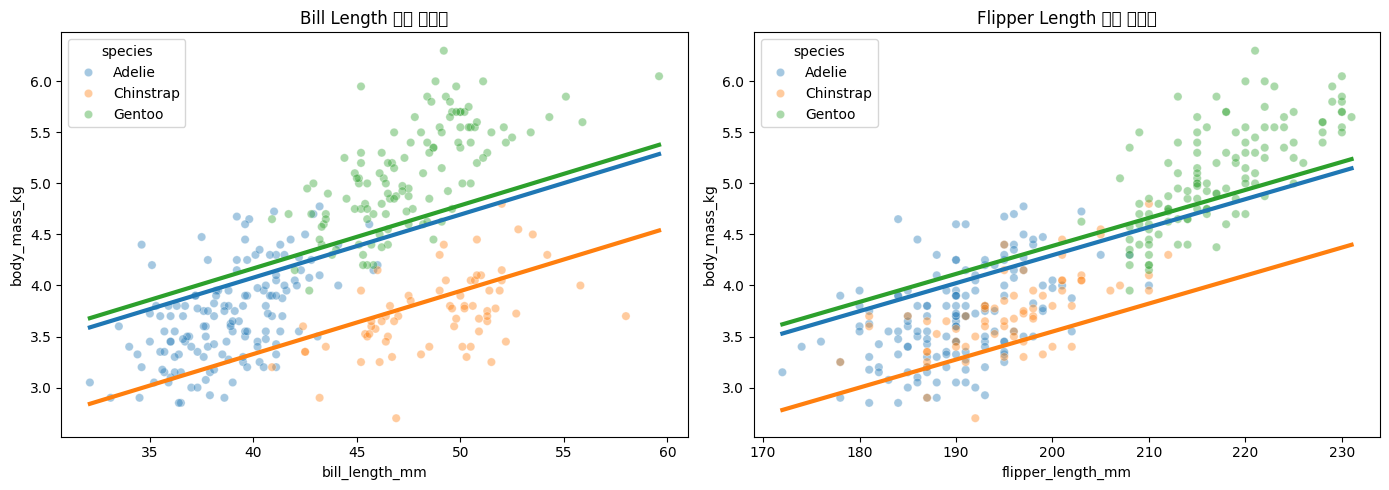

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. bill_length 기준
sns.scatterplot(
    data=penguins2,
    x='bill_length_mm',
    y='body_mass_kg',
    hue='species',
    alpha=0.4,
    ax=axes[0]
)

sns.lineplot(
    data=pred_df[pred_df['feature'] == 'bill'],
    x='bill_length_mm',
    y='pred',
    hue='species',
    linewidth=3,
    ax=axes[0],
    legend=False
)

axes[0].set_title('Bill Length 기준 예측선')
axes[0].set_xlabel('bill_length_mm')
axes[0].set_ylabel('body_mass_kg')


# 2. flipper_length 기준
sns.scatterplot(
    data=penguins2,
    x='flipper_length_mm',
    y='body_mass_kg',
    hue='species',
    alpha=0.4,
    ax=axes[1]
)

sns.lineplot(
    data=pred_df[pred_df['feature'] == 'flipper'],
    x='flipper_length_mm',
    y='pred',
    hue='species',
    linewidth=3,
    ax=axes[1],
    legend=False
)

axes[1].set_title('Flipper Length 기준 예측선')
axes[1].set_xlabel('flipper_length_mm')
axes[1].set_ylabel('body_mass_kg')

plt.tight_layout()
plt.show()